In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


def clean(v, nd=3):
    """Приводит numpy-значения к обычным python для аккуратной печати."""
    if isinstance(v, np.generic):
        v = v.item()
    return round(v, nd) if isinstance(v, float) else v

In [2]:
from sklearn.model_selection import train_test_split

df = pd.read_csv("Titanic-Dataset.csv")

X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()
y = df["Survived"]

title = df["Name"].str.extract(r",\s*([^.]+)\.", expand=False)
X["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (712, 8) | test: (179, 8)


**Baseline** - Random Forest с параметрами из lab2 (`n_estimators=70, max_depth=6, min_samples_leaf=5, min_samples_split=6`). Это точка отсчёта для всей работы. Пока считаем только его качество на кросс-валидации по train; на test baseline будет оценён в самом конце вместе с остальными моделями.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, accuracy_score
from sklearn.base import clone

num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Sex", "Embarked", "Title"]

prep = make_column_transformer(
    (SimpleImputer(strategy="median"), num_cols),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder()), cat_cols))


P = "randomforestclassifier__" 

baseline = make_pipeline(prep, RandomForestClassifier(n_estimators=70, max_depth=6, min_samples_leaf=5, min_samples_split=6, random_state=RANDOM_STATE))
print("Baseline:", dict(n_estimators=70, max_depth=6, min_samples_leaf=5, min_samples_split=6))

Baseline: {'n_estimators': 70, 'max_depth': 6, 'min_samples_leaf': 5, 'min_samples_split': 6}


## Гиперпараметры RandomForestClassifier

Для подбора выбраны пять параметров.

| Параметр | Смысл | Диапазон | Ожидаемое влияние |
|---|---|---|---|
| `n_estimators` | число деревьев в лесу | 20-150 | больше деревьев - ниже дисперсия ансамбля; после некоторого порога качество не растёт, а растёт только время. Переобучения от числа деревьев не ожидается |
| `max_depth` | максимальная глубина каждого дерева | 2-10| мало - недообучение (деревья не успевают выучить взаимодействия признаков); много - деревья запоминают шум train |
| `min_samples_leaf` | минимум объектов в листе | 1-10 | малое значение - сложные деревья, склонные к переобучению; большое - сильное сглаживание и риск недообучения |
| `max_features` | доля (или число) признаков, рассматриваемых при каждом разбиении | `sqrt`, 0.1-1.0 | мало - деревья более разнообразны и менее коррелированы, но каждое слабее; много - деревья сильнее, но похожи друг на друга. Эффект заранее неочевиден, зависит от числа информативных признаков |
| `min_samples_split` | Минимальное число объектов в узле дерева, при котором алгоритм вообще пытается разбить этот узел дальше. Если в узле объектов меньше этого значения, он сразу становится листом | 1...10, целые числа | чем больше значение, тем проще деревья, меньше риск переобучения, но выше риск недообучения |

Сложность модели растёт с увеличением `max_depth` и `max_features` и уменьшением `min_samples_leaf`; `n_estimators` влияет скорее на стабильность, чем на сложность.


## 3. Кросс-валидация

Используется **стратифицированная 5-fold CV с перемешиванием** на обучающей выборке. Почему 5: train небольшой, поэтому каждый фолд должен оставаться достаточно большим, чтобы оценка F1 на нём не была слишком шумной, и при этом модель в каждом фолде обучается на большей части данных. 10 фолдов дали бы чуть менее смещённую оценку, но вдвое дороже по времени и с более шумной оценкой на каждом маленьком фолде. Стратификация сохраняет долю выживших в каждом фолде.

**Зачем нужна кросс-валидация.** Она даёт оценку качества на данных, которые модель не видела при обучении, используя при этом все данные train по очереди и для обучения, и для проверки. Заодно появляется не одно число, а набор значений, по которому видно разброс.

**Почему одного разбиения train/test недостаточно для подбора параметров.** Оценка на одной части данных зависит от того, какие именно объекты в неё попали. Ниже это видно на примере: один и тот же baseline на разных разбиениях получает заметно разные оценки. При сравнении близких конфигураций такой шум легко принять за реальное преимущество. Кроме того, если подбирать параметры по test, у нас не останется данных для честной оценки.

**Что будет, если многократно выбирать гиперпараметры по результату на test.** Test перестаёт быть независимым: мы выбираем конфигурацию, которой «повезло» именно на этих объектах. Итоговая оценка получится завышенной, а реальное качество на новых данных - ниже. Это косвенная утечка информации из test в модель, поэтому в работе test используется только один раз, для финальной проверки уже выбранных решений.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

base_scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1")
print("Baseline, F1 по фолдам:", base_scores.round(3))
print(f"Baseline, CV F1 = {base_scores.mean():.3f} ± {base_scores.std():.3f}")

Baseline, F1 по фолдам: [0.774 0.733 0.824 0.731 0.729]
Baseline, CV F1 = 0.758 ± 0.037


## 4. Grid Search

Сетка небольшая и содержит значения, которые покрывают режимы от простых до сложных моделей по каждому параметру: перебираются все комбинации. Поиск идёт по train с 5-fold CV, метрика F1. Для анализа сохраняется и качество на обучающих частях фолдов (`return_train_score`).

In [23]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    P + "n_estimators": np.arange(50, 80, 10),
    P + "max_depth": list(np.arange(2, 8, 1)) + [None],
    P + "min_samples_leaf": np.arange(1, 10, 1),
    P + "max_features": ["sqrt", 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
}
n_grid = int(np.prod([len(v) for v in param_grid.values()]))
print("Комбинаций в сетке:", n_grid, "| обучений модели (с учётом 5 фолдов):", n_grid * 5)

grid = GridSearchCV(baseline, param_grid, cv=cv, scoring="f1", n_jobs=-1, return_train_score=True)
t0 = time.perf_counter()
grid.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

print(f"Время поиска: {grid_time:.1f} c")
print("Лучшие параметры:", {k.replace(P, ""): clean(v) for k, v in grid.best_params_.items()})
print(f"Лучший CV F1: {grid.best_score_:.3f}")

Комбинаций в сетке: 2079 | обучений модели (с учётом 5 фолдов): 10395
Время поиска: 241.7 c
Лучшие параметры: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 50}
Лучший CV F1: 0.774


### Random Search

In [37]:
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

param_rand = {
    P + "n_estimators": randint(20, 100),
    P + "max_depth": randint(2, 8),
    P + "min_samples_split": randint(1, 10),
    P + "min_samples_leaf": randint(1, 10),
    P + "max_features": uniform(0.1, 1.0)
}

n_iter = 200

rand_search = RandomizedSearchCV(baseline, param_distributions=param_rand, n_iter=n_iter, cv=cv, scoring="f1", n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True)
t0 = time.perf_counter()
rand_search.fit(X_train, y_train)
rand_time = time.perf_counter() - t0

print(f"Время поиска: {rand_time:.1f} c")
print("Лучшие параметры:", {k.replace(P, ""): clean(v) for k, v in rand_search.best_params_.items()})
print(f"Лучший CV F1: {rand_search.best_score_:.3f}")

Время поиска: 10.2 c
Лучшие параметры: {'max_depth': 5, 'max_features': 0.305, 'min_samples_leaf': 6, 'min_samples_split': 4, 'n_estimators': 38}
Лучший CV F1: 0.769


,Комбинаций,Обучений (×5 фолдов),Лучший CV F1,"Время, с"
Grid Search,2079,10395,0.774,241.669
Random Search,200,1000,0.769,10.186


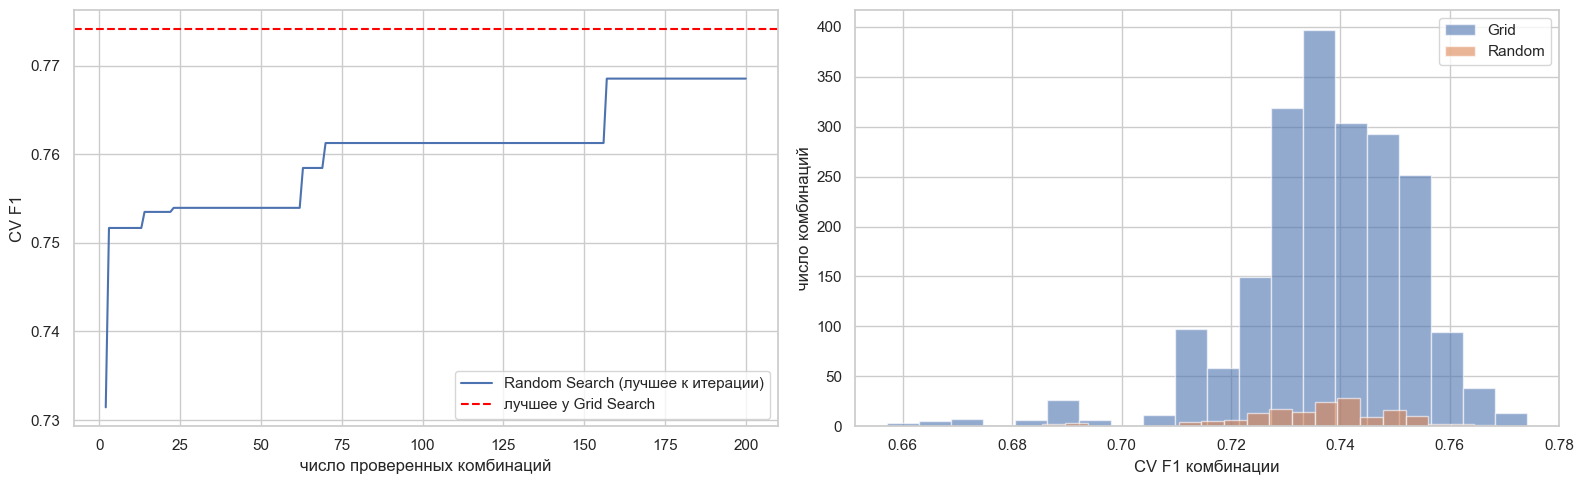

Топ-5 Grid:


,mean_test_score,std_test_score,mean_train_score
0,0.774,0.027,0.918
1,0.773,0.024,0.917
2,0.772,0.033,0.919
3,0.771,0.027,0.918
4,0.770,0.025,0.916


Топ-5 Random:


,mean_test_score,std_test_score,mean_train_score
0,0.769,0.037,0.788
1,0.763,0.044,0.772
2,0.761,0.028,0.791
3,0.758,0.039,0.774
4,0.758,0.042,0.793


In [40]:
summary = pd.DataFrame({
    "Комбинаций": [n_grid, n_iter],
    "Обучений (×5 фолдов)": [n_grid * 5, n_iter * 5],
    "Лучший CV F1": [grid.best_score_, rand_search.best_score_],
    "Время, с": [grid_time, rand_time],
}, index=["Grid Search", "Random Search"])
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
r = pd.DataFrame(rand_search.cv_results_)
axes[0].plot(np.arange(1, n_iter + 1), r["mean_test_score"].cummax().ffill(), label="Random Search (лучшее к итерации)")
axes[0].axhline(grid.best_score_, color="red", ls="--", label="лучшее у Grid Search")
axes[0].set_xlabel("число проверенных комбинаций")
axes[0].set_ylabel("CV F1")
axes[0].legend()

axes[1].hist(pd.DataFrame(grid.cv_results_)["mean_test_score"], bins=20, alpha=0.6, label="Grid")
axes[1].hist(r["mean_test_score"], bins=20, alpha=0.6, label="Random")
axes[1].set_xlabel("CV F1 комбинации")
axes[1].set_ylabel("число комбинаций")
axes[1].legend()
plt.tight_layout()
plt.show()

for name, s in [("Grid", grid), ("Random", rand_search)]:
    cols = ["mean_test_score", "std_test_score", "mean_train_score"]
    top = pd.DataFrame(s.cv_results_).sort_values("mean_test_score", ascending=False).head(5)
    print(f"Топ-5 {name}:")
    display(top[cols].round(3).reset_index(drop=True))

**Сравнение.** Качество, найденное двумя методами, практически одинаково: разница намного меньше разброса между фолдами, то есть её нельзя считать значимой. При этом Random Search проверил гораздо меньше комбинаций и потратил кратно меньше времени. Лучшие конфигурации заметно различаются по параметрам, но дают сопоставимый результат.

**Когда случайный поиск предпочтительнее полного перебора:**
- параметров много, и сетка растёт экспоненциально, а бюджет ограничен;
- параметры непрерывные или с большим числом значений: случайный поиск пробует больше разных значений каждого параметра, а сетка - только несколько заранее выбранных;
- не все параметры одинаково важны: при сетке много комбинаций отличаются только в неважном параметре, а случайный поиск при том же бюджете исследует важные параметры гуще;
- поиск можно остановить в любой момент и получить рабочий результат, а неполная сетка даёт перекошенную картину.